# Filtro de calidad — calibración de umbrales

Calibra los umbrales de `src/common/quality_filter.py` con las 3,662 fotos:

1. **Nueva medida de nitidez.** En el EDA las fotos "más borrosas" resultaron ser las más oscuras, porque la
   varianza del Laplaciano baja con poco contraste. Ahora se divide entre el brillo² y se deja fuera la orilla de la
   retina. Se compara contra la medida anterior.
2. **Ver las fotos** cerca de los posibles umbrales, para elegirlos a ojo y no solo por percentil.
3. **Revisar a quién rechaza:** el filtro no debe castigar a una clase ni a una cámara en particular.
4. **Probar** con fotos buenas a las que se les agrega desenfoque u oscuridad.
5. **Imprimir las constantes** para copiarlas a `quality_filter.py`.

**Cómo correrlo (SageMaker Studio):** *Run All*. La primera vez mide las 3,662 fotos (unos minutos) y lo guarda en
`DATA_DIR/quality_scores.csv`. Para ajustar umbrales solo hay que cambiar la celda de la sección 4 y volver a correr
de ahí para abajo.

In [1]:
import os
import sys
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))

try:
    from dotenv import load_dotenv
    load_dotenv(REPO / ".env")
except ImportError:
    pass

from src.common import quality_filter as qf
from src.common.preprocess import crop_retina, load_image

DATA_DIR = Path(os.environ.get("DATA_DIR", REPO / "data" / "aptos")).expanduser()
CLASS_NAMES = {0: "Sin retinopatía", 1: "Leve", 2: "Moderada", 3: "Severa", 4: "Proliferativa"}
plt.rcParams["figure.dpi"] = 90

labels = pd.read_csv(DATA_DIR / "train.csv")
old = pd.read_csv(DATA_DIR / "image_stats.csv")[["id_code", "height", "width", "blur", "brightness"]]
old = old.rename(columns={"blur": "old_blur", "brightness": "old_brightness"})
splits = pd.read_csv(REPO / "data" / "splits.csv")[["id_code", "split"]]
print(f"DATA_DIR = {DATA_DIR} · {len(labels)} imágenes")

DATA_DIR = /home/sagemaker-user/data/aptos · 3662 imágenes


## 1. Medir todas las fotos

Se guarda junto con los parámetros de la medición (`QUALITY_SIZE`, `EDGE_MARGIN`): si cambian en `quality_filter.py`,
se vuelve a medir.

In [2]:
VERSION = f"size={qf.QUALITY_SIZE},margin={qf.EDGE_MARGIN}"
cache = DATA_DIR / "quality_scores.csv"


def measure(image_id):
    img = load_image(DATA_DIR / "train_images" / f"{image_id}.png")
    return {"id_code": image_id, **qf.quality_scores(img)}


scores = pd.read_csv(cache) if cache.exists() else pd.DataFrame(columns=["id_code", "version"])
scores = scores[scores.version == VERSION]
missing = sorted(set(labels.id_code) - set(scores.id_code))
if missing:
    print(f"Midiendo {len(missing)} fotos...")
    with ThreadPoolExecutor(max_workers=os.cpu_count()) as pool:
        new = pd.DataFrame(pool.map(measure, missing)).assign(version=VERSION)
    scores = pd.concat([scores, new], ignore_index=True)
    scores.to_csv(cache, index=False)

df = labels.merge(scores, on="id_code").merge(old, on="id_code").merge(splits, on="id_code", how="left")
df["split"] = df.split.fillna("quitada (duplicado)")
df["resolution"] = df.height.astype(int).astype(str) + "×" + df.width.astype(int).astype(str)
df[["brightness", "sharpness", "old_blur"]].describe(percentiles=[0.005, 0.01, 0.02, 0.05, 0.5]).round(2)

,brightness,sharpness,old_blur
count,3662.00,3662.00,3662.00
mean,88.55,3.76,54.64
std,20.72,2.79,24.03
min,28.84,0.25,4.68
0.5%,36.41,0.60,8.07
1%,40.11,0.65,9.01
2%,44.92,0.75,10.89
5%,50.33,1.03,15.57
50%,91.92,3.24,56.42
max,156.13,32.55,184.67


## 2. Medida anterior contra la nueva

Si la nueva medida funciona, la nitidez ya no debe depender del brillo: en la gráfica de la derecha las fotos oscuras
(izquierda del eje x) no deberían quedar todas abajo.

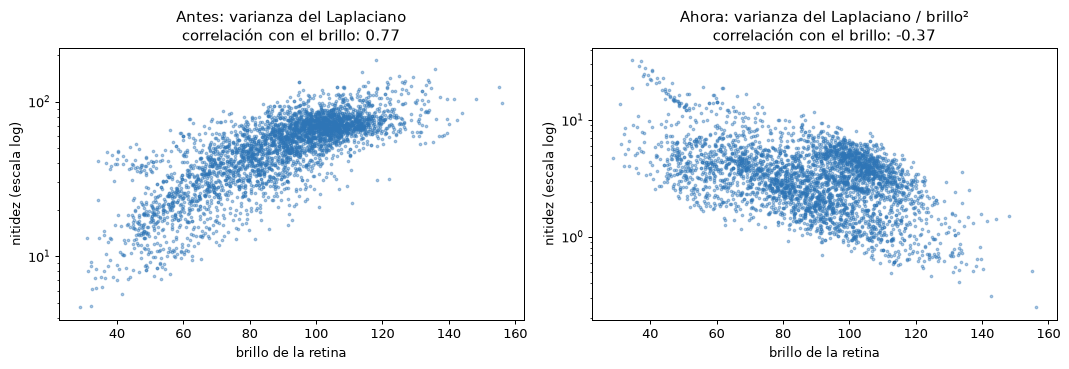

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, col, title in [(axes[0], "old_blur", "Antes: varianza del Laplaciano"),
                       (axes[1], "sharpness", "Ahora: varianza del Laplaciano / brillo²")]:
    ax.scatter(df.brightness, df[col], s=4, alpha=0.4, color="#2e75b6")
    ax.set_yscale("log"); ax.set_xlabel("brillo de la retina"); ax.set_ylabel("nitidez (escala log)")
    rho = df.brightness.corr(df[col], method="spearman")
    ax.set_title(f"{title}\ncorrelación con el brillo: {rho:.2f}")
plt.tight_layout()
plt.show()

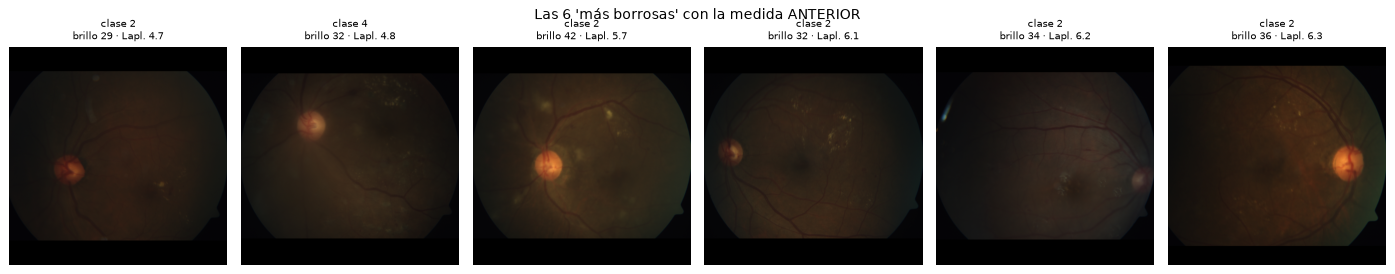

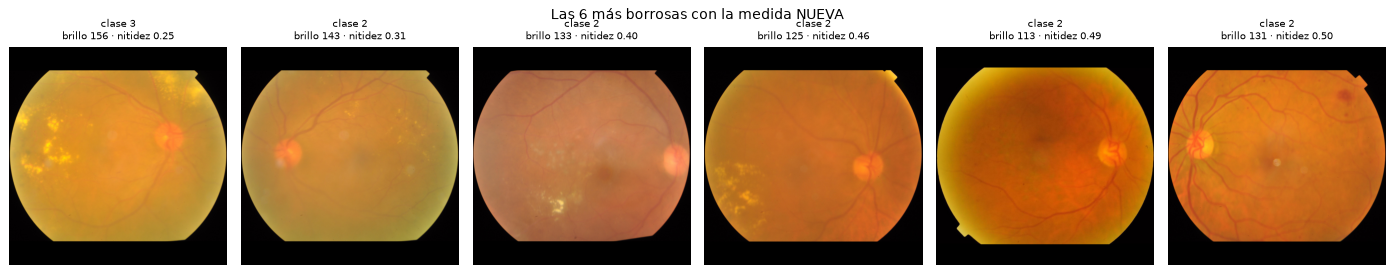

In [4]:
LABELS = {"brightness": "brillo", "sharpness": "nitidez", "old_blur": "Lapl."}
FORMATS = {"brightness": ".0f", "sharpness": ".2f", "old_blur": ".1f"}


def show_row(rows, title, value_cols=("brightness", "sharpness"), n=6):
    rows = rows.head(n)
    fig, axes = plt.subplots(1, n, figsize=(2.6 * n, 3.1))
    for ax in np.atleast_1d(axes):
        ax.axis("off")
    for ax, (_, r) in zip(np.atleast_1d(axes), rows.iterrows()):
        ax.imshow(crop_retina(load_image(DATA_DIR / "train_images" / f"{r.id_code}.png")))
        values = " · ".join(f"{LABELS[c]} {r[c]:{FORMATS[c]}}" for c in value_cols)
        ax.set_title(f"clase {r.diagnosis}\n{values}", fontsize=8)
    fig.suptitle(title, fontsize=11)
    plt.tight_layout()
    plt.show()


show_row(df.nsmallest(6, "old_blur"), "Las 6 'más borrosas' con la medida ANTERIOR", ("brightness", "old_blur"))
show_row(df.nsmallest(6, "sharpness"), "Las 6 más borrosas con la medida NUEVA")

## 3. Ver fotos cerca de los posibles umbrales

Cada fila muestra fotos alrededor de un percentil. Sirve para decidir hasta dónde una foto todavía se puede leer.

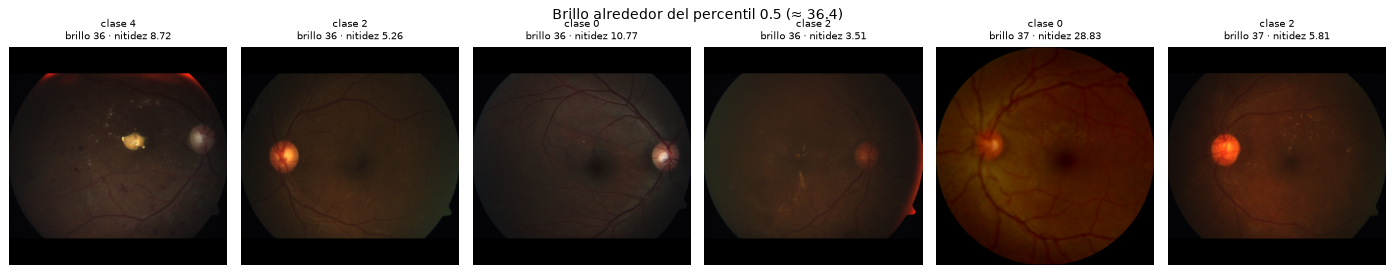

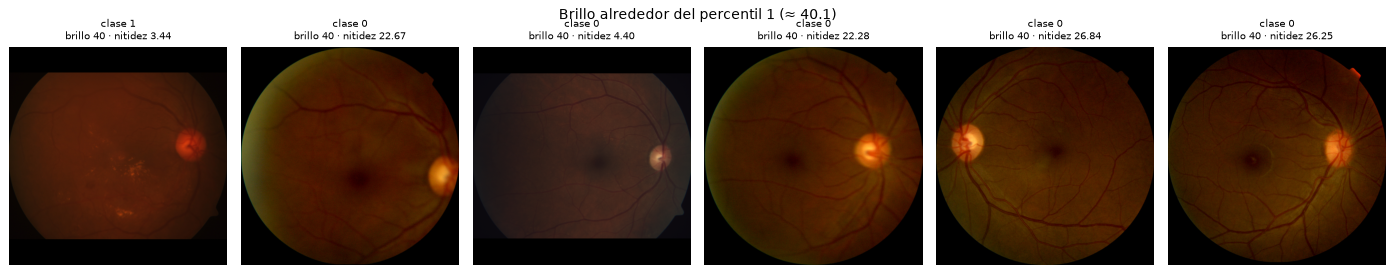

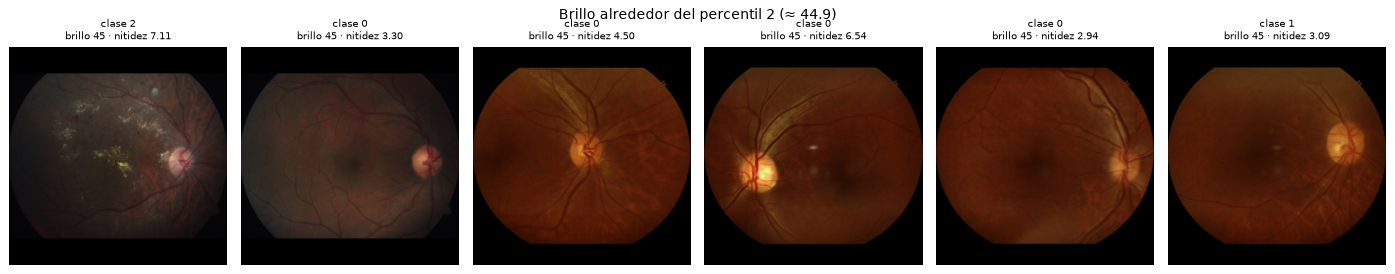

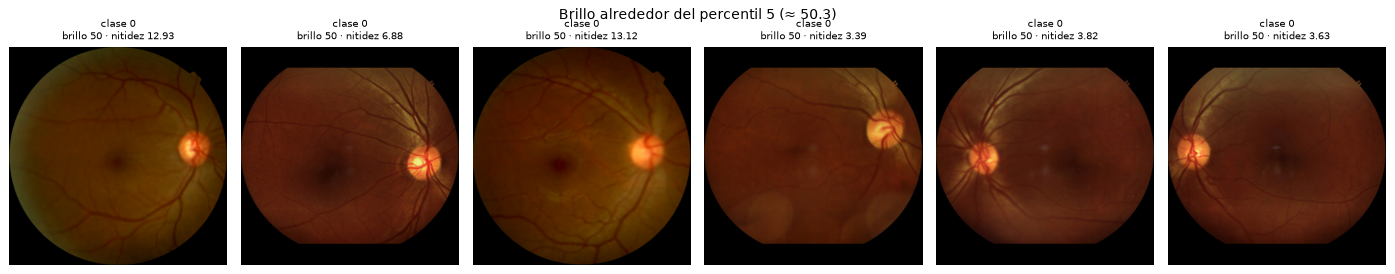

In [5]:
def around_percentile(col, pct, n=6):
    value = np.percentile(df[col], pct)
    return df.iloc[(df[col] - value).abs().argsort()[:n]].sort_values(col)


for pct in [0.5, 1, 2, 5]:
    show_row(around_percentile("brightness", pct), f"Brillo alrededor del percentil {pct} (≈ {np.percentile(df.brightness, pct):.1f})")

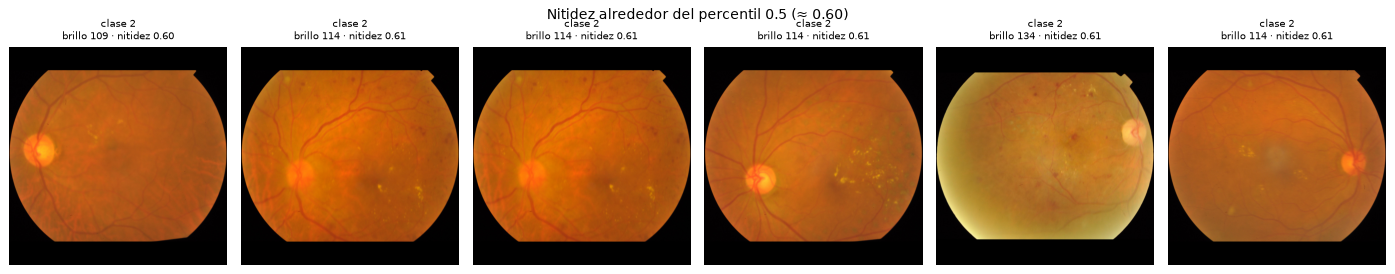

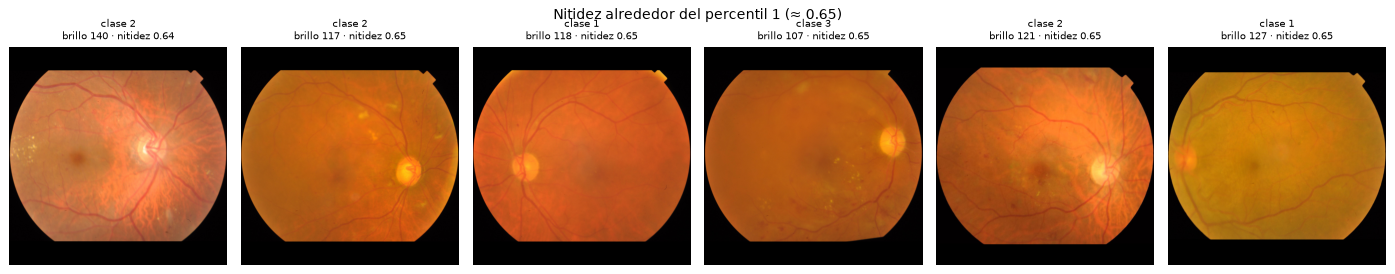

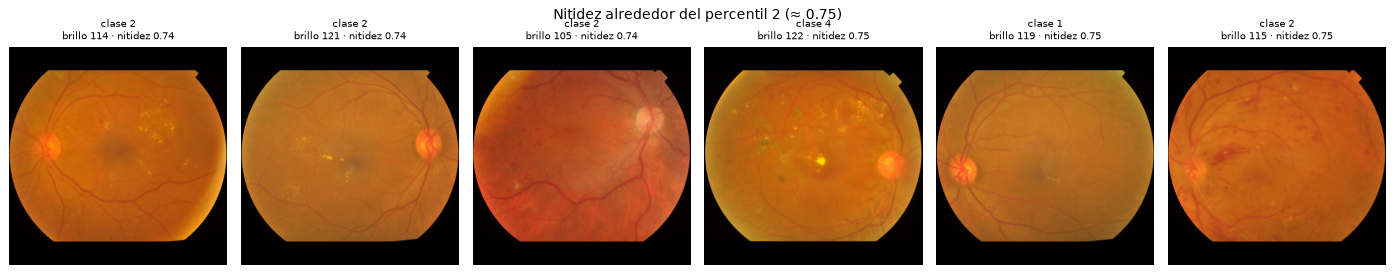

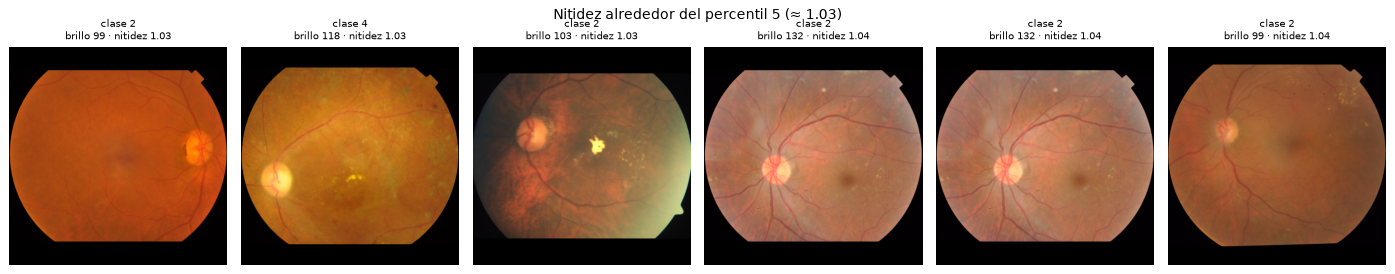

In [6]:
for pct in [0.5, 1, 2, 5]:
    show_row(around_percentile("sharpness", pct), f"Nitidez alrededor del percentil {pct} (≈ {np.percentile(df.sharpness, pct):.2f})")

## 4. Elegir umbrales

**Ajustar aquí** después de ver las filas de arriba: el umbral queda en el percentil elegido. Lo que interesa es
rechazar las fotos que de verdad no se pueden leer, no un porcentaje fijo.

In [7]:
BRIGHTNESS_PERCENTILE = 0.5
SHARPNESS_PERCENTILE = 0.5

brightness_threshold = round(float(np.percentile(df.brightness, BRIGHTNESS_PERCENTILE)), 1)
sharpness_threshold = round(float(np.percentile(df.sharpness, SHARPNESS_PERCENTILE)), 2)

df["reason"] = np.select(
    [df.brightness < brightness_threshold, df.sharpness < sharpness_threshold], ["oscura", "borrosa"], default="ok")
rejected = df.reason != "ok"
print(f"Umbrales: brillo < {brightness_threshold} → oscura · nitidez < {sharpness_threshold} → borrosa")
print(f"Se rechaza el {100 * rejected.mean():.1f}% ({rejected.sum()} fotos):", df.reason[rejected].value_counts().to_dict())

Umbrales: brillo < 36.4 → oscura · nitidez < 0.6 → borrosa
Se rechaza el 1.0% (38 fotos): {'borrosa': 19, 'oscura': 19}


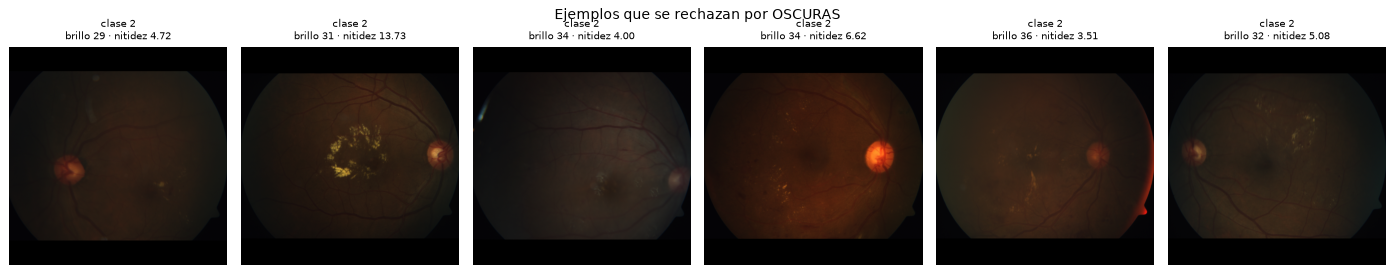

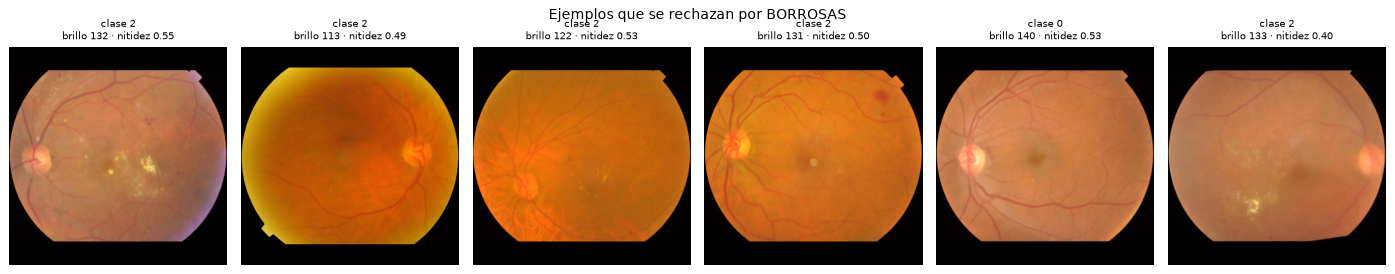

In [8]:
show_row(df[df.reason == "oscura"].sample(min(6, (df.reason == "oscura").sum()), random_state=0), "Ejemplos que se rechazan por OSCURAS")
show_row(df[df.reason == "borrosa"].sample(min(6, (df.reason == "borrosa").sum()), random_state=0), "Ejemplos que se rechazan por BORROSAS")

### ¿A quién rechaza?

Si el filtro rechaza mucho más una clase o una cámara, el sistema pediría repetir la foto más seguido a ciertos
pacientes o clínicas. Comparamos el % rechazado de cada grupo contra el promedio.

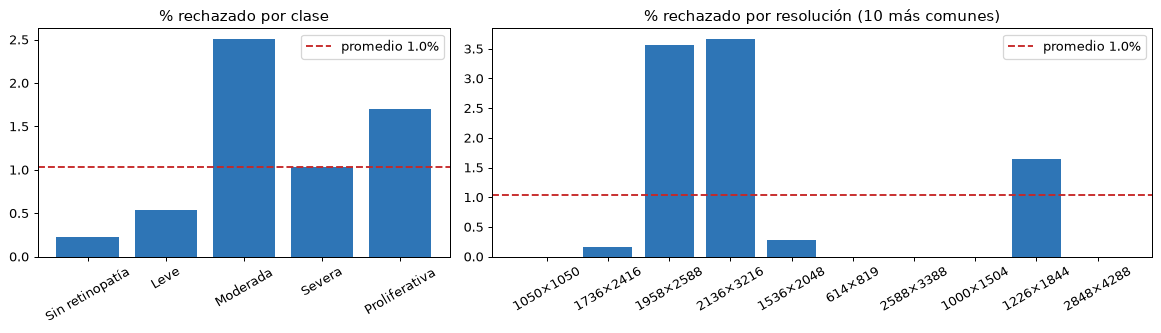

Por clase (%): {0: 0.2, 1: 0.5, 2: 2.5, 3: 1.0, 4: 1.7}
Por resolución (%): {'1050×1050': 0.0, '1736×2416': 0.2, '1958×2588': 3.6, '2136×3216': 3.7, '1536×2048': 0.3, '614×819': 0.0, '2588×3388': 0.0, '1000×1504': 0.0, '1226×1844': 1.6, '2848×4288': 0.0}


In [9]:
by_class = df.groupby("diagnosis").apply(lambda g: 100 * (g.reason != "ok").mean(), include_groups=False)
top_res = df.resolution.value_counts().index[:10]
by_res = df[df.resolution.isin(top_res)].groupby("resolution").apply(lambda g: 100 * (g.reason != "ok").mean(), include_groups=False).loc[top_res]
average = 100 * rejected.mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].bar([CLASS_NAMES[c] for c in by_class.index], by_class.values, color="#2e75b6")
axes[1].bar(by_res.index, by_res.values, color="#2e75b6")
for ax, title in [(axes[0], "% rechazado por clase"), (axes[1], "% rechazado por resolución (10 más comunes)")]:
    ax.axhline(average, color="#c62828", ls="--", label=f"promedio {average:.1f}%")
    ax.set_title(title); ax.legend(); ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
print("Por clase (%):", by_class.round(1).to_dict())
print("Por resolución (%):", by_res.round(1).to_dict())

## 5. Prueba con fotos degradadas

Tomamos fotos de prueba que pasan el filtro y les agregamos desenfoque u oscuridad, para ver que el filtro las
detecta con los umbrales elegidos.

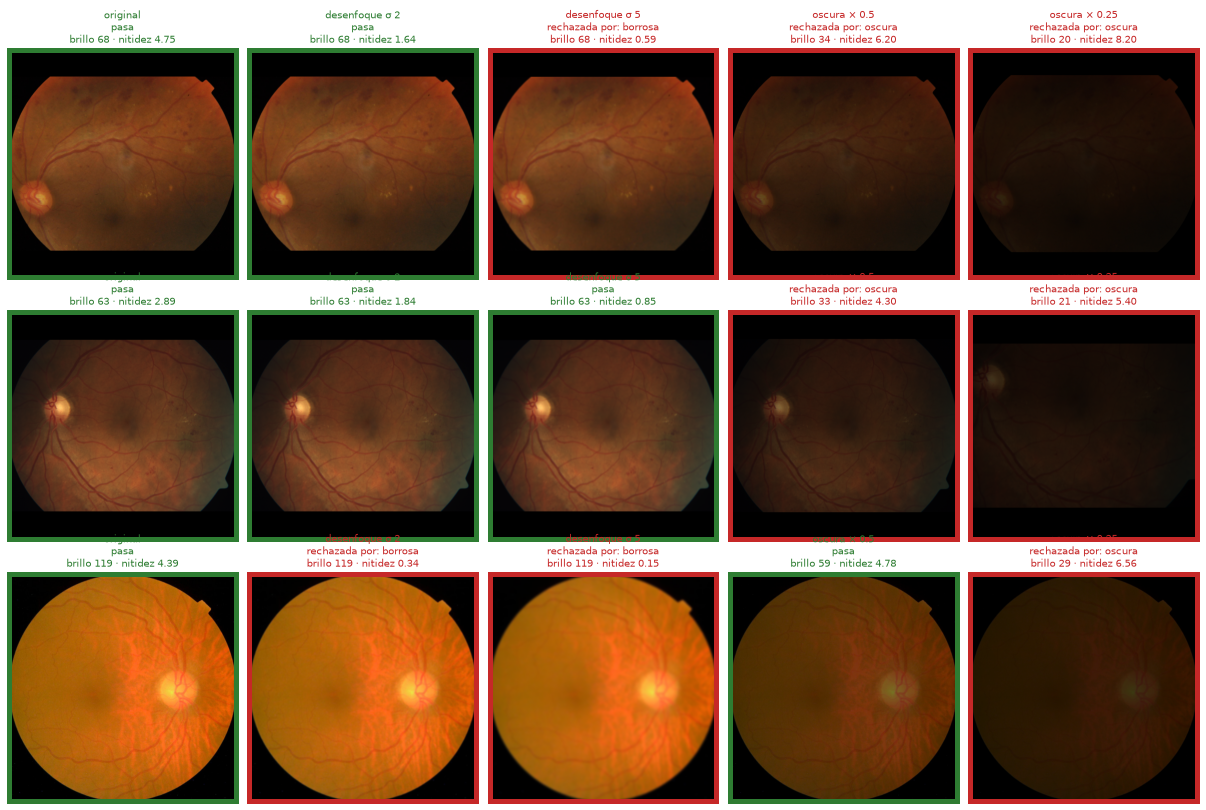

In [10]:
def degrade(img, kind):
    if kind == "original":
        return img
    if kind.startswith("desenfoque"):
        return cv2.GaussianBlur(img, (0, 0), float(kind.split()[-1]))
    factor = float(kind.split()[-1])
    return np.clip(img.astype(np.float32) * factor, 0, 255).astype(np.uint8)


kinds = ["original", "desenfoque σ 2", "desenfoque σ 5", "oscura × 0.5", "oscura × 0.25"]
sample = df[(df.split == "test") & (df.reason == "ok")].sample(3, random_state=1)

fig, axes = plt.subplots(len(sample), len(kinds), figsize=(2.7 * len(kinds), 3 * len(sample)), squeeze=False)
for row, (_, r) in enumerate(sample.iterrows()):
    img = load_image(DATA_DIR / "train_images" / f"{r.id_code}.png")
    for col, kind in enumerate(kinds):
        out = degrade(img, kind)
        res = qf.check_quality(out, brightness_threshold, sharpness_threshold)
        ax = axes[row, col]
        ax.imshow(crop_retina(out)); ax.set_xticks([]); ax.set_yticks([])
        color = "#2e7d32" if res.ok else "#c62828"
        for side in ax.spines.values():
            side.set_edgecolor(color); side.set_linewidth(4)
        verdict = "pasa" if res.ok else f"rechazada por: {res.reason}"
        ax.set_title(f"{kind}\n{verdict}\nbrillo {res.scores['brightness']:.0f} · nitidez {res.scores['sharpness']:.2f}", fontsize=8, color=color)
plt.tight_layout()
plt.show()

## 6. Constantes para `quality_filter.py`

In [11]:
print("# Copiar a src/common/quality_filter.py (salen de notebooks/quality.ipynb)")
print(f"BRIGHTNESS_THRESHOLD = {brightness_threshold}   # percentil {BRIGHTNESS_PERCENTILE}; menor = oscura")
print(f"SHARPNESS_THRESHOLD = {sharpness_threshold}     # percentil {SHARPNESS_PERCENTILE}; menor = borrosa")

# Copiar a src/common/quality_filter.py (salen de notebooks/quality.ipynb)
BRIGHTNESS_THRESHOLD = 36.4   # percentil 0.5; menor = oscura
SHARPNESS_THRESHOLD = 0.6     # percentil 0.5; menor = borrosa


## 7. Conclusiones

Llenar después de correr el notebook:

- **Medida nueva contra la anterior:** …
- **Umbrales elegidos:** …
- **A quién rechaza:** …
- **Prueba con fotos degradadas:** …